<a href="https://colab.research.google.com/github/DivakarShenoy/Machine-Learning-Portfolio-Divakar-Shenoy/blob/main/Divakar_Shenoy_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import time

### Download the Fashion-MNIST dataset

The Fashion-MNIST dataset contains 70,000 grayscale images of clothing items in 10 classes, with 7,000 images per class. The dataset is divided into 60,000 training images and 10,000 testing images. Each image is 28x28 pixels. The classes are mutually exclusive and there is no overlap between them.

In [42]:
a=60000
(train_images, train_labels), (test_images, test_labels) = datasets.fashion_mnist.load_data()
train_images = train_images[:a]
train_labels = train_labels[:a]
train_images = train_images.astype("float32")
train_images = (train_images - 127.5) / 127.5
# Add a channel dimension (28, 28) -> (28, 28, 1) since the images are grayscale
train_images = train_images.reshape((train_images.shape[0], 28, 28, 1))
test_images = test_images.reshape((test_images.shape[0], 28, 28, 1))

# Scale pixel values to be between 0 and 1
# this is messing up the pixel values train_images, test_images = train_images / 255.0, test_images / 255.0

# make labels one-hot representation
train_labels_one_hot = tf.one_hot(train_labels, 10)
test_labels_one_hot = tf.one_hot(test_labels, 10)
train_labels_one_hot = train_labels_one_hot[:a]

### Verify the data

To verify that the dataset looks correct, let's plot the first 25 images from the training set and display the class name below each image.

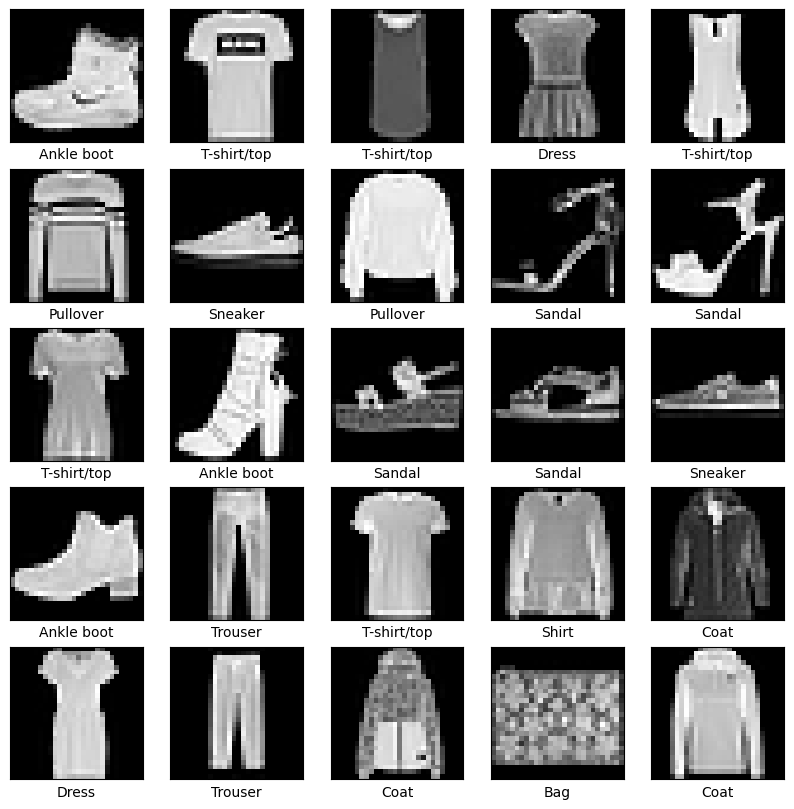

In [43]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i].reshape(28, 28), cmap='gray')
    plt.xlabel(class_names[train_labels[i]])
plt.show()

### Build Model

In [44]:
# TODO
# Build your own model'
tf.random.set_seed(42)
np.random.seed(42)

print("Data Shape", train_images.shape)
BUFFER_SHAPE = 60000
BATCH_SIZE = 256
train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(BUFFER_SHAPE).batch(BATCH_SIZE)

latent_dim = 100

def build_generator():
  model = models.Sequential(name="generator") #make the generator sequential
  model.add(layers.Dense(7*7*256, use_bias = False, input_shape=(latent_dim,)))
  model.add(layers.BatchNormalization())
  model.add(layers.LeakyReLU())
  model.add(layers.Reshape((7,7,256)))

  model.add(layers.Conv2DTranspose(128, (5,5), strides = (1,1), padding="same", use_bias=False))
  model.add(layers.BatchNormalization())
  model.add(layers.LeakyReLU())

  model.add(layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding="same", use_bias=False))
  model.add(layers.BatchNormalization())
  model.add(layers.LeakyReLU())

  model.add(layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding="same",use_bias=False, activation="tanh"))

  return model

generator = build_generator()
generator.summary()


Data Shape (60000, 28, 28, 1)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_17 (LeakyReLU)      │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_18 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

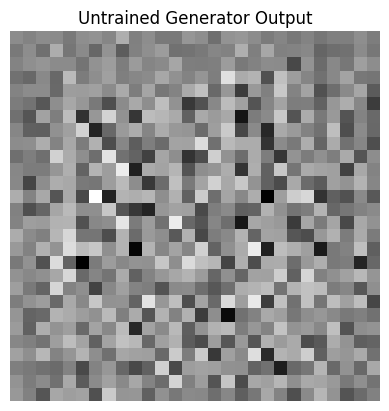

In [45]:
#generate some noise to tets
noise = tf.random.normal([1, latent_dim])
generated_image = generator(noise, training=False)

plt.imshow(generated_image[0,:,:,0], cmap="gray")
plt.title("Untrained Generator Output")
plt.axis("off")
plt.show()

In [46]:
def build_discriminator():
  modeld = models.Sequential(name="discriminator")
  modeld.add(layers.Conv2D(32, (5,5), strides=(2,2), padding="same"))
  modeld.add(layers.LeakyReLU())
  modeld.add(layers.Conv2D(64, (5,5), strides=(2,2), padding="same"))
  modeld.add(layers.LeakyReLU())
  modeld.add(layers.Conv2D(128, (5,5), strides=(2,2), padding="same"))
  modeld.add(layers.LeakyReLU())
  modeld.add(layers.Dropout(0.3))

  modeld.add(layers.Flatten())
  modeld.add(layers.Dense(1))
  return modeld
discriminator = build_discriminator()
discriminator.summary()



Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_21 (LeakyReLU)      │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_22 (LeakyReLU)      │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [47]:
#check if discriminator is working
dec = discriminator(generated_image)
print("Output logit(probability): ", float(dec[0,0]) )
#the low output probability indicates that the discriminator can tell fake photos



Output logit(probability):  -0.0010518132476136088


In [48]:
# binary cross entropy for logits, so definietly for this 1 is real, 0 is fake
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
def discriminator_loss(asli_out,nasli_out):
  real_loss = cross_entropy(tf.ones_like(asli_out), asli_out)
  fake_loss = cross_entropy(tf.zeros_like(nasli_out), nasli_out)
  return real_loss + fake_loss
def gen_loss(nasli_out):
  return cross_entropy(tf.ones_like(nasli_out), nasli_out)

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4,beta_1=0.5) #scientific notation
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4,beta_1=0.5)
#adam does something to speed it up



In [49]:
#training thing
@tf.function
def train_step(images):
  batch_size = tf.shape(images)[0]
  noise = tf.random.normal([batch_size, latent_dim])
  with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gena_loss = gen_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

  gradients_of_generator = gen_tape.gradient(gena_loss, generator.trainable_variables)
  gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

  generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
  discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

  return gena_loss, disc_loss

In [50]:
#train our generative adversarial network
seed = tf.random.normal([16, latent_dim]) #try changing random state

def generate_and_plot(model, test_input): #we can show every once in a while
    predictions = model(test_input, training=False)
    plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)

        plt.imshow(predictions[i, :, :, 0] * 0.5 + 0.5, cmap="gray")
        plt.axis("off")
    plt.show()


Epoch 1/100  gen_loss=0.670  disc_loss=1.394  time=14.5s
Epoch 2/100  gen_loss=0.701  disc_loss=1.346  time=9.7s
Epoch 3/100  gen_loss=0.757  disc_loss=1.264  time=9.8s
Epoch 4/100  gen_loss=0.757  disc_loss=1.255  time=9.9s
Epoch 5/100  gen_loss=0.732  disc_loss=1.316  time=10.1s


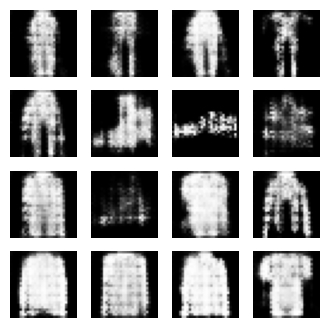

Epoch 6/100  gen_loss=0.800  disc_loss=1.347  time=10.1s
Epoch 7/100  gen_loss=0.813  disc_loss=1.284  time=10.2s
Epoch 8/100  gen_loss=0.754  disc_loss=1.290  time=10.3s
Epoch 9/100  gen_loss=0.821  disc_loss=1.267  time=10.3s
Epoch 10/100  gen_loss=0.813  disc_loss=1.345  time=10.5s


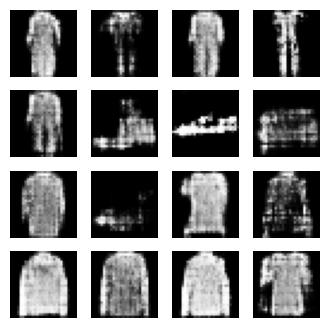

Epoch 11/100  gen_loss=0.794  disc_loss=1.308  time=10.5s
Epoch 12/100  gen_loss=0.827  disc_loss=1.275  time=10.6s
Epoch 13/100  gen_loss=0.782  disc_loss=1.331  time=10.7s
Epoch 14/100  gen_loss=0.693  disc_loss=1.335  time=10.7s
Epoch 15/100  gen_loss=0.775  disc_loss=1.357  time=10.7s


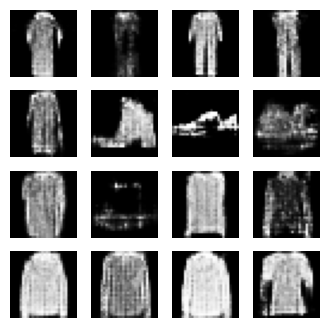

Epoch 16/100  gen_loss=0.803  disc_loss=1.295  time=10.8s
Epoch 17/100  gen_loss=0.703  disc_loss=1.341  time=10.8s
Epoch 18/100  gen_loss=0.764  disc_loss=1.322  time=10.9s
Epoch 19/100  gen_loss=0.819  disc_loss=1.291  time=10.9s
Epoch 20/100  gen_loss=0.722  disc_loss=1.435  time=10.9s


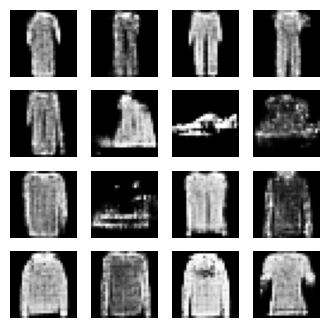

Epoch 21/100  gen_loss=0.783  disc_loss=1.319  time=11.0s
Epoch 22/100  gen_loss=0.894  disc_loss=1.302  time=11.0s
Epoch 23/100  gen_loss=0.757  disc_loss=1.293  time=11.0s
Epoch 24/100  gen_loss=0.732  disc_loss=1.326  time=11.0s
Epoch 25/100  gen_loss=0.858  disc_loss=1.318  time=11.0s


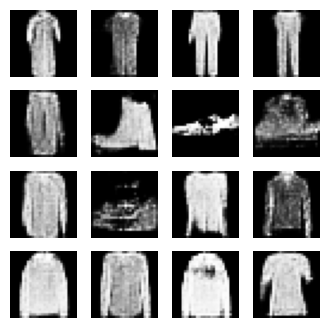

Epoch 26/100  gen_loss=0.734  disc_loss=1.328  time=11.0s
Epoch 27/100  gen_loss=0.760  disc_loss=1.328  time=11.0s
Epoch 28/100  gen_loss=0.753  disc_loss=1.360  time=11.0s
Epoch 29/100  gen_loss=0.783  disc_loss=1.338  time=11.1s
Epoch 30/100  gen_loss=0.827  disc_loss=1.280  time=11.1s


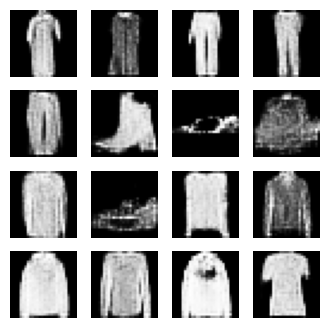

Epoch 31/100  gen_loss=0.781  disc_loss=1.253  time=11.1s
Epoch 32/100  gen_loss=0.820  disc_loss=1.368  time=11.0s
Epoch 33/100  gen_loss=0.655  disc_loss=1.352  time=11.0s
Epoch 34/100  gen_loss=0.742  disc_loss=1.322  time=11.0s
Epoch 35/100  gen_loss=0.778  disc_loss=1.294  time=11.0s


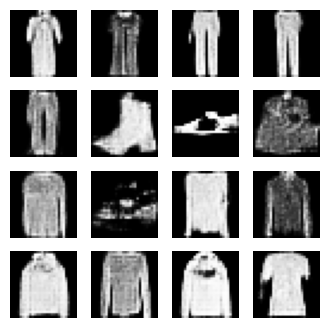

Epoch 36/100  gen_loss=0.784  disc_loss=1.318  time=11.0s
Epoch 37/100  gen_loss=0.772  disc_loss=1.302  time=11.0s
Epoch 38/100  gen_loss=0.862  disc_loss=1.329  time=11.1s
Epoch 39/100  gen_loss=0.836  disc_loss=1.292  time=11.1s
Epoch 40/100  gen_loss=0.718  disc_loss=1.304  time=11.0s


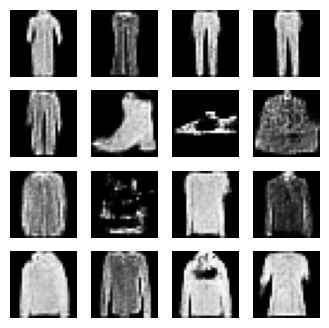

Epoch 41/100  gen_loss=0.714  disc_loss=1.342  time=11.0s
Epoch 42/100  gen_loss=0.799  disc_loss=1.348  time=11.0s
Epoch 43/100  gen_loss=0.807  disc_loss=1.267  time=11.0s
Epoch 44/100  gen_loss=0.782  disc_loss=1.325  time=11.0s
Epoch 45/100  gen_loss=0.769  disc_loss=1.306  time=11.1s


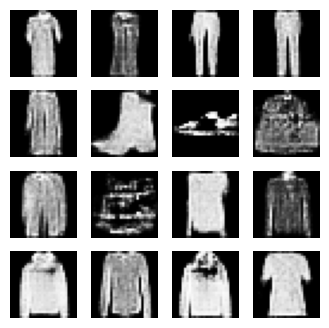

Epoch 46/100  gen_loss=0.781  disc_loss=1.338  time=11.0s
Epoch 47/100  gen_loss=0.855  disc_loss=1.365  time=11.1s
Epoch 48/100  gen_loss=0.811  disc_loss=1.298  time=11.0s
Epoch 49/100  gen_loss=0.755  disc_loss=1.312  time=11.1s
Epoch 50/100  gen_loss=0.765  disc_loss=1.267  time=11.0s


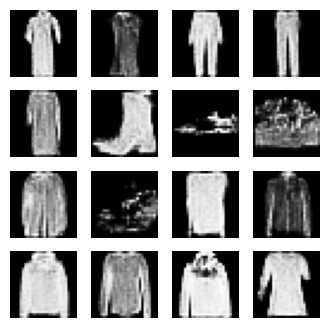

Epoch 51/100  gen_loss=0.752  disc_loss=1.356  time=11.0s
Epoch 52/100  gen_loss=0.757  disc_loss=1.323  time=11.0s
Epoch 53/100  gen_loss=0.667  disc_loss=1.341  time=11.1s
Epoch 54/100  gen_loss=0.783  disc_loss=1.300  time=11.1s
Epoch 55/100  gen_loss=0.692  disc_loss=1.301  time=11.0s


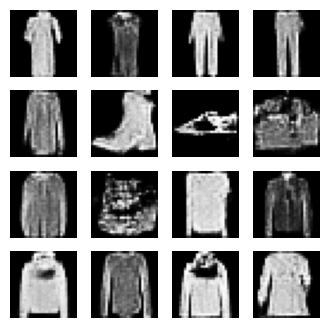

Epoch 56/100  gen_loss=0.828  disc_loss=1.289  time=11.1s
Epoch 57/100  gen_loss=0.797  disc_loss=1.339  time=11.0s
Epoch 58/100  gen_loss=0.784  disc_loss=1.338  time=11.0s
Epoch 59/100  gen_loss=0.703  disc_loss=1.334  time=11.0s
Epoch 60/100  gen_loss=0.843  disc_loss=1.189  time=11.0s


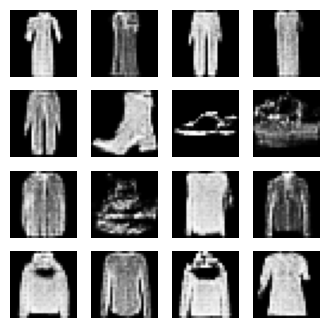

Epoch 61/100  gen_loss=0.762  disc_loss=1.296  time=11.0s
Epoch 62/100  gen_loss=0.778  disc_loss=1.339  time=11.0s
Epoch 63/100  gen_loss=0.678  disc_loss=1.346  time=11.0s
Epoch 64/100  gen_loss=0.806  disc_loss=1.320  time=11.1s
Epoch 65/100  gen_loss=0.814  disc_loss=1.310  time=11.1s


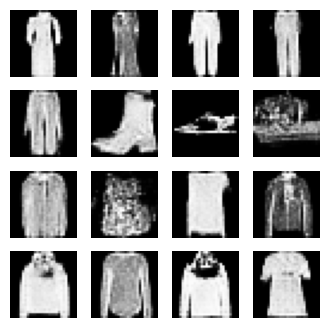

Epoch 66/100  gen_loss=0.846  disc_loss=1.304  time=11.1s
Epoch 67/100  gen_loss=0.785  disc_loss=1.353  time=11.0s
Epoch 68/100  gen_loss=0.656  disc_loss=1.397  time=11.1s
Epoch 69/100  gen_loss=0.683  disc_loss=1.356  time=11.1s
Epoch 70/100  gen_loss=0.832  disc_loss=1.309  time=11.1s


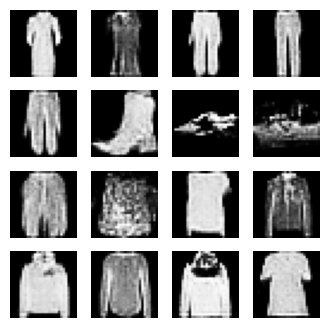

Epoch 71/100  gen_loss=0.737  disc_loss=1.323  time=20.5s
Epoch 72/100  gen_loss=0.789  disc_loss=1.369  time=10.9s
Epoch 73/100  gen_loss=0.844  disc_loss=1.299  time=11.2s
Epoch 74/100  gen_loss=0.882  disc_loss=1.294  time=11.5s
Epoch 75/100  gen_loss=0.700  disc_loss=1.407  time=11.1s


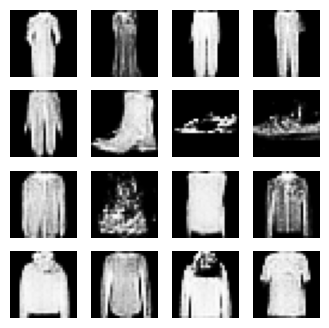

Epoch 76/100  gen_loss=0.796  disc_loss=1.310  time=11.0s
Epoch 77/100  gen_loss=0.793  disc_loss=1.300  time=10.9s
Epoch 78/100  gen_loss=0.742  disc_loss=1.319  time=10.9s
Epoch 79/100  gen_loss=0.717  disc_loss=1.388  time=11.0s
Epoch 80/100  gen_loss=0.765  disc_loss=1.342  time=11.0s


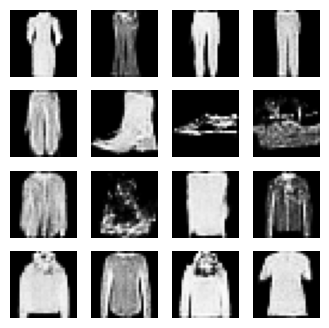

Epoch 81/100  gen_loss=0.937  disc_loss=1.349  time=11.1s
Epoch 82/100  gen_loss=0.774  disc_loss=1.301  time=11.1s
Epoch 83/100  gen_loss=0.879  disc_loss=1.286  time=11.0s
Epoch 84/100  gen_loss=0.855  disc_loss=1.321  time=11.0s
Epoch 85/100  gen_loss=0.759  disc_loss=1.312  time=11.0s


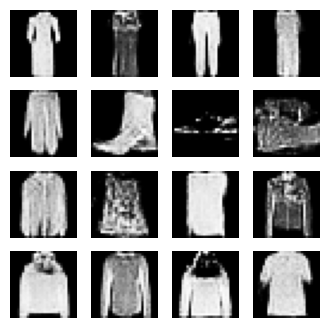

Epoch 86/100  gen_loss=0.722  disc_loss=1.280  time=11.0s
Epoch 87/100  gen_loss=0.869  disc_loss=1.329  time=11.0s
Epoch 88/100  gen_loss=0.749  disc_loss=1.270  time=11.0s
Epoch 89/100  gen_loss=0.826  disc_loss=1.336  time=11.0s
Epoch 90/100  gen_loss=0.859  disc_loss=1.314  time=11.0s


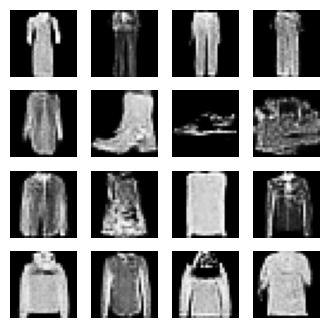

Epoch 91/100  gen_loss=0.710  disc_loss=1.301  time=11.0s
Epoch 92/100  gen_loss=0.732  disc_loss=1.281  time=11.0s
Epoch 93/100  gen_loss=0.797  disc_loss=1.316  time=11.0s
Epoch 94/100  gen_loss=0.793  disc_loss=1.328  time=11.0s
Epoch 95/100  gen_loss=0.868  disc_loss=1.318  time=11.0s


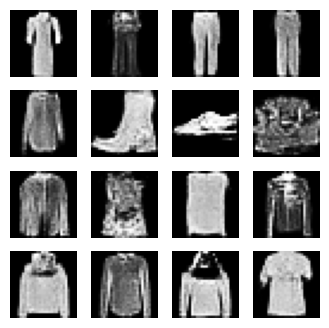

Epoch 96/100  gen_loss=0.810  disc_loss=1.312  time=20.5s
Epoch 97/100  gen_loss=0.897  disc_loss=1.317  time=11.0s
Epoch 98/100  gen_loss=0.846  disc_loss=1.250  time=11.1s
Epoch 99/100  gen_loss=0.778  disc_loss=1.320  time=11.3s
Epoch 100/100  gen_loss=0.702  disc_loss=1.281  time=11.1s


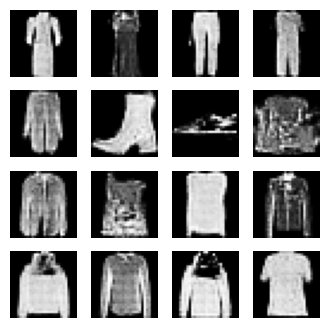

In [51]:
# epoch stuff
epo = 100
for epoch in range(epo):
  start = time.time() #for keeping track of time
  gena_loss = disc_loss = 0.0 #generator and discriminator loss intialization
  for image_batch in train_dataset:
    gena_loss, disc_loss = train_step(image_batch)
  print(f"Epoch {epoch + 1}/{epo}  "
        f"gen_loss={float(gena_loss):.3f}  disc_loss={float(disc_loss):.3f}  "
        f"time={time.time() - start:.1f}s")
  if (epoch+1)%5 == 0:
    generate_and_plot(generator, seed)


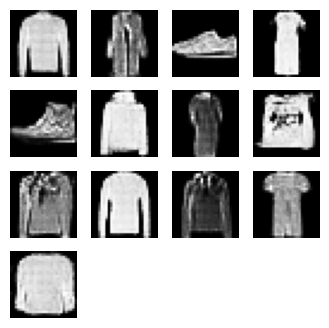

In [57]:
new_noise = tf.random.normal([13, latent_dim])
generate_and_plot(generator, new_noise)